#Ridge,Lasso,ElasticNet  performed on cancer data

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression,Ridge

In [ ]:
df = pd.read_csv('/content/Cancer_Data.csv')
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [ ]:
df.shape

(569, 33)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


<Axes: xlabel='radius_mean', ylabel='diagnosis'>

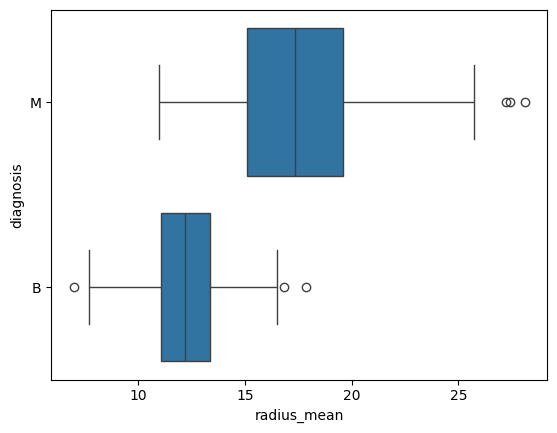

In [ ]:
import seaborn as sns
sns.boxplot(x='radius_mean',y='diagnosis',data=df)

<Axes: xlabel='texture_mean', ylabel='diagnosis'>

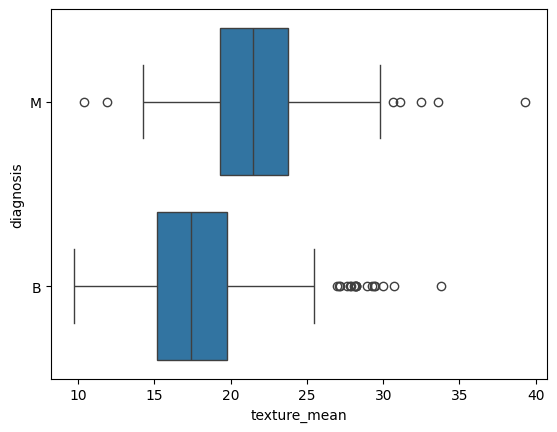

In [ ]:
sns.boxplot(x='texture_mean',y='diagnosis',data=df)

<Axes: xlabel='perimeter_mean', ylabel='diagnosis'>

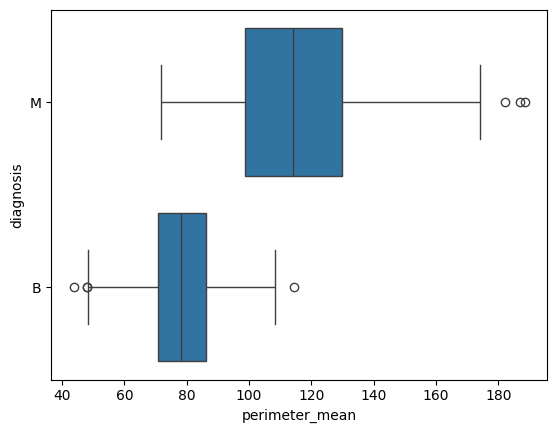

In [ ]:
sns.boxplot(x='perimeter_mean',y='diagnosis',data=df)

<Axes: xlabel='area_mean', ylabel='diagnosis'>

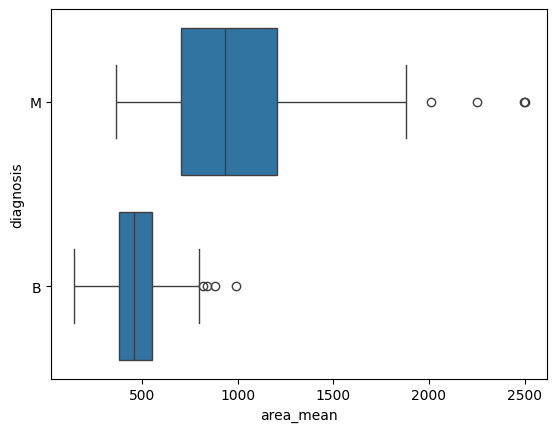

In [ ]:
sns.boxplot(x='area_mean',y='diagnosis',data=df)

<Axes: xlabel='smoothness_mean', ylabel='diagnosis'>

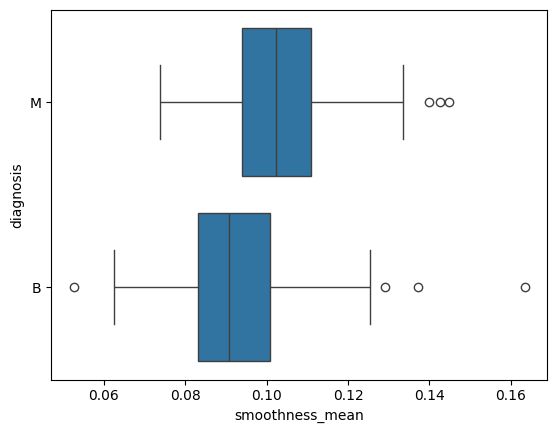

In [ ]:
sns.boxplot(x='smoothness_mean',y='diagnosis',data=df)

<Axes: xlabel='compactness_mean', ylabel='diagnosis'>

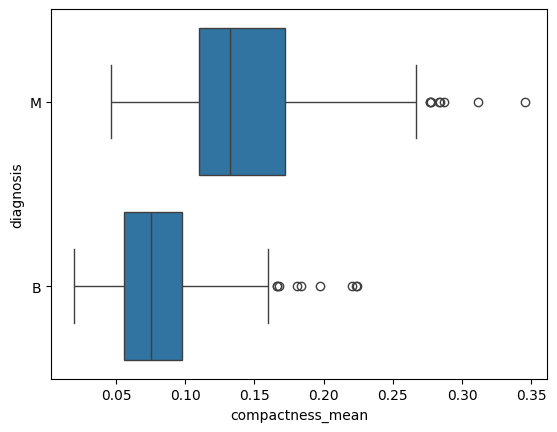

In [ ]:
sns.boxplot(x='compactness_mean',y='diagnosis',data=df)

<Axes: xlabel='concavity_se', ylabel='diagnosis'>

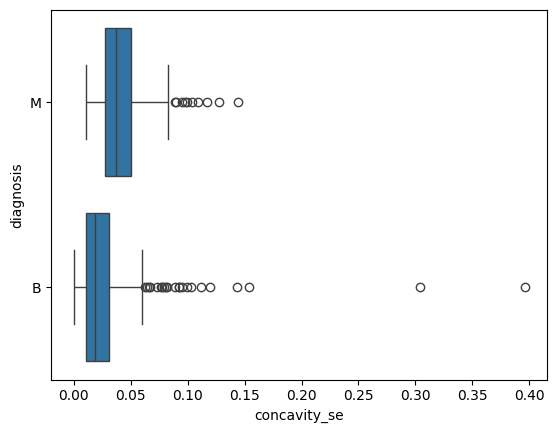

In [ ]:
sns.boxplot(x='concavity_se',y='diagnosis',data=df)

<Axes: xlabel='concave points_se', ylabel='diagnosis'>

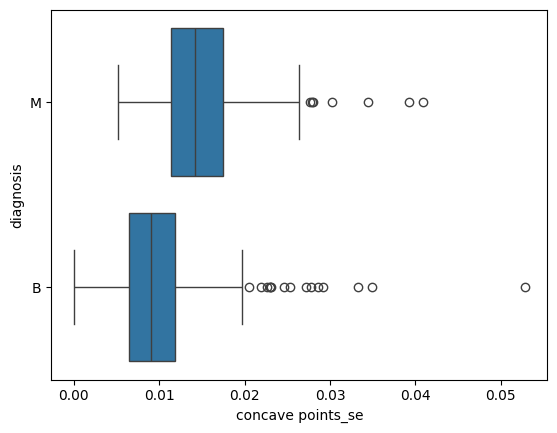

In [ ]:
sns.boxplot(x='concave points_se',y='diagnosis',data=df)

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])

In [ ]:
q3 = df['diagnosis'].quantile(0.75)
q1 = df['diagnosis'].quantile(0.25)
iqr = q3-q1

In [ ]:
ul = q3+1.5*iqr
ll = q1-1.5*iqr

In [ ]:
upper = np.where(df['diagnosis']>=ul)
lower = np.where(df['diagnosis']<=ll)

In [ ]:
df.drop(upper[0],inplace=True)
df.drop(lower[0],inplace=True)

In [ ]:
x = df.iloc[:,2:10]
x

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430
...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200


In [ ]:
y = df.iloc[:,1].values

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
lr = LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [ ]:
lr.score(x_train,y_train)

0.6843448812759371

In [ ]:
rr = Ridge(alpha=0.01)
rr.fit(x_test,y_test)

Ridge(alpha=0.01)

In [ ]:
rr.score(x_test,y_test)

0.6856897397642104

In [ ]:
rr = Ridge(alpha=0.001)
rr.fit(x_test,y_test)

Ridge(alpha=0.001)

In [ ]:
rr.score(x_test,y_test)

0.6914276681676914

In [ ]:
rr.predict([[23.29,58.06,126.3,2310,0.11,0.86,0.81,0.1]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


array([0.06904806])

### Even after removing the outliers the result is same as the previous one so i think there was no problem in previous model

## Lasso Regression

In [ ]:
from sklearn.linear_model import Lasso,ElasticNet

In [ ]:
names = df.columns[2:10]
names

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean'],
      dtype='object')

In [ ]:
rng = range(len(names))
rng

range(0, 8)

In [ ]:
ls = Lasso(alpha=0.1)

In [ ]:
data = ls.fit(x,y)

In [ ]:
cf = data.coef_
cf

array([-0.        ,  0.01553518,  0.02397029, -0.000718  ,  0.        ,
        0.        ,  0.        ,  0.        ])

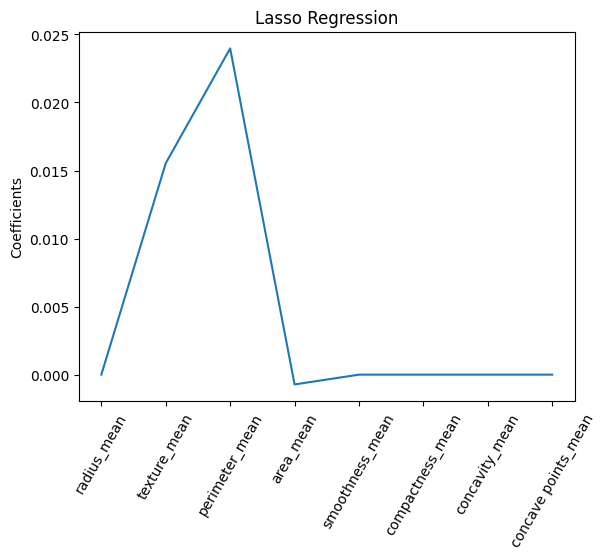

In [ ]:
import matplotlib.pyplot as plt
plt.plot(rng,cf)
plt.xticks(rng,names,rotation=60)
plt.ylabel("Coefficients")
plt.title("Lasso Regression")
plt.show()

In [ ]:
data.predict([[23.29,58.06,126.3,2310,0.11,0.86,0.81,0.1]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(


array([0.60944339])

In [ ]:
data.predict([[29.36,11.89,52.23,996,0.119,0.07891,0.001,0.2618]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(


array([-0.93984501])

##ElasticNET Regression

In [ ]:
es = ElasticNet(l1_ratio=0.5)

In [ ]:
model = es.fit(x,y)

In [ ]:
es_cf =model.coef_
es_cf

array([0.        , 0.        , 0.00254776, 0.00079733, 0.        ,
       0.        , 0.        , 0.        ])

In [ ]:
import numpy as np
n = np.argmax(es_cf)
n

np.int64(2)

In [ ]:
print("The most influencing column=",names[n])

The most influencing column= perimeter_mean


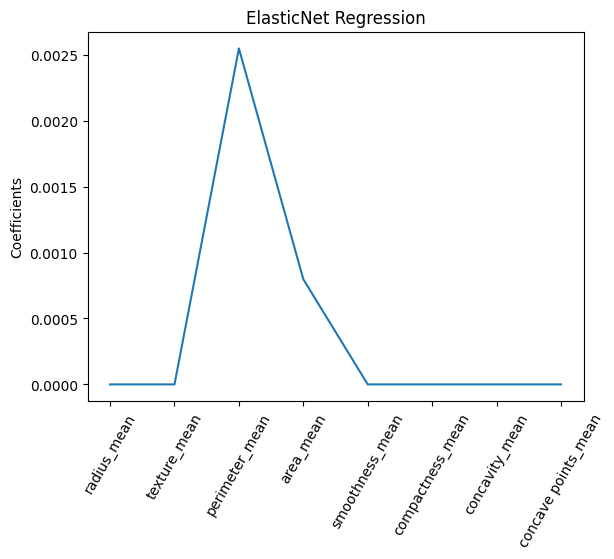

In [ ]:
plt.plot(rng,es_cf)
plt.xticks(rng,names,rotation=60)
plt.ylabel("Coefficients")
plt.title("ElasticNet Regression")
plt.show()

In [ ]:
model.predict([[23.29,58.06,126.3,2310,0.11,0.86,0.81,0.1],[29.36,11.89,52.23,996,0.119,0.07891,0.001,0.2618]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(


array([1.77972567, 0.54331688])